# Walkthrough: a tiny VLM, end to end

This notebook goes through the repo piece by piece using the `tiny` config (~2M parameters, 64x64 images), so the whole thing runs on a laptop CPU in a couple of minutes.

1. the toy dataset
2. what shapes flow through the model
3. training it to caption shapes
4. why the KV cache matters
5. what the paged KV cache is actually doing
6. ONNX export and int8 quantization

The real benchmark numbers come from `python -m benchmark.runner` with the bigger `compact` model; this is for understanding, not for timing.

In [1]:
import sys, time, logging, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")  # ONNX export tracer warnings, not useful here
logging.getLogger().setLevel(logging.ERROR)  # onnxruntime.quantization logs a preprocessing hint

import torch
import matplotlib.pyplot as plt

from vlm import VLMConfig, MultimodalTransformer, SyntheticMultimodalDataset, train_synthetic_vlm, caption_accuracy, decode_caption
from vlm.scheduler import Request, run_continuous_batching

torch.manual_seed(0)
cfg = VLMConfig.tiny()

## 1. The data

There's no real dataset here. Each image is one coloured square or circle in one of four quadrants, and the caption says what and where. That's 3 colours x 2 shapes x 4 positions = 24 possible captions.

It's deliberately easy - the goal is to check that the caption loss actually trains the vision encoder, not to build a useful captioner. A model that ignores the image can only learn the caption *template* and then has to guess the colour/shape/position.

input_ids: [1, 4, 7, 9, 10, 11, 12, 15, 0, 0, 0, 0, 0, 0, 0, 0]
labels:    [4, 7, 9, 10, 11, 12, 15, 2, 0, 0, 0, 0, 0, 0, 0, 0]
decoded:   a blue circle in the top right


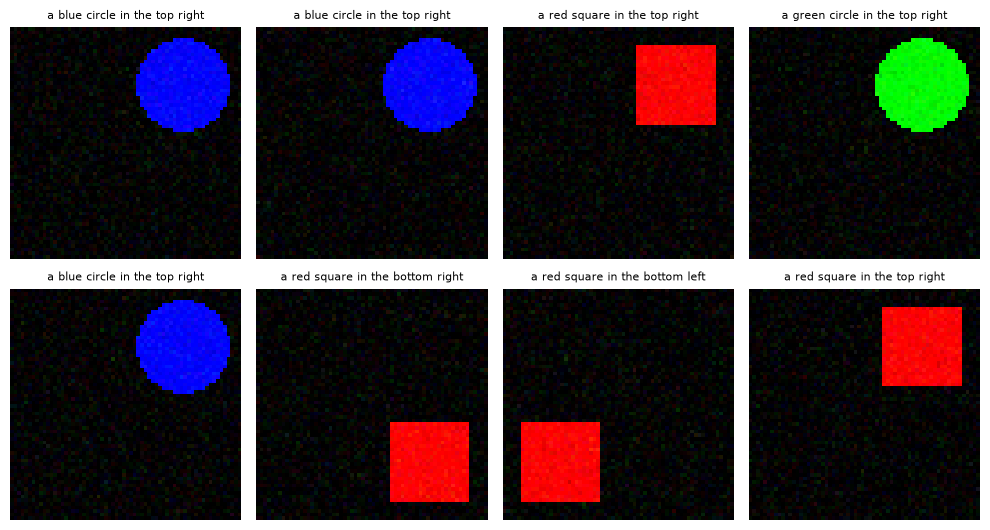

In [2]:
ds = SyntheticMultimodalDataset(num_samples=8, image_size=cfg.vision.image_size, seed=0)

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax, img, cap in zip(axes.flat, ds.images, ds.captions):
    ax.imshow(img.clamp(0, 1).permute(1, 2, 0))
    ax.set_title(cap, fontsize=8)
    ax.axis("off")
plt.tight_layout()

print("input_ids:", ds.input_ids[0].tolist())
print("labels:   ", ds.labels[0].tolist())
print("decoded:  ", decode_caption(ds.input_ids[0]))

`labels` is just `input_ids` shifted left by one (0 is padding and is ignored by the loss).

## 2. Shapes through the model

Image -> ViT patches -> projector -> concatenated in front of the text embeddings -> decoder.

In [3]:
model = MultimodalTransformer(cfg).eval()
for k, v in model.parameter_breakdown().items():
    print(f"{k:22s} {v:>10,}")

images, ids = ds.images[:2], ds.input_ids[:2]
with torch.no_grad():
    patches = model.vision_encoder(images)
    projected = model.projector(patches)
    text = model.decoder.embed_tokens(ids)
    logits, _ = model(images, ids)

print()
print("images        ", tuple(images.shape))
print("vision output ", tuple(patches.shape), f"  <- {cfg.vision.num_patches} patches + CLS")
print("projected     ", tuple(projected.shape), "  <- now in the decoder's width")
print("text embeds   ", tuple(text.shape))
print("logits        ", tuple(logits.shape), "  <- one prediction per position, image positions included")

vision_encoder            497,536
multimodal_projector       62,080
language_decoder        1,574,208
total                   2,133,824

images         (2, 3, 64, 64)
vision output  (2, 17, 128)   <- 16 patches + CLS
projected      (2, 17, 192)   <- now in the decoder's width
text embeds    (2, 16, 192)
logits         (2, 33, 2048)   <- one prediction per position, image positions included


## 3. Training

Before training the model just produces random tokens:

In [4]:
prompt = torch.ones(4, 1, dtype=torch.long)  # just <bos>
before = model.generate(ds.images[:4], prompt, max_new_tokens=10)
for row, cap in zip(before, ds.captions[:4]):
    print(f"{cap:32s} -> {decode_caption(row[1:])}")

a blue circle in the top right   -> <1925> <1925> <1925> <1925> <1925> <1925> <1925> <1925> <1925> <1925>
a blue circle in the top right   -> <325> <325> <325> <325> <325> <325> <325> <325> <325> <325>
a red square in the top right    -> <979> <979> <979> <979> <979> <979> <979> <979> <979> <979>
a green circle in the top right  -> <337> <337> <337> <337> <337> <337> <337> <337> <337> <337>


63s, loss 7.06 -> 0.025


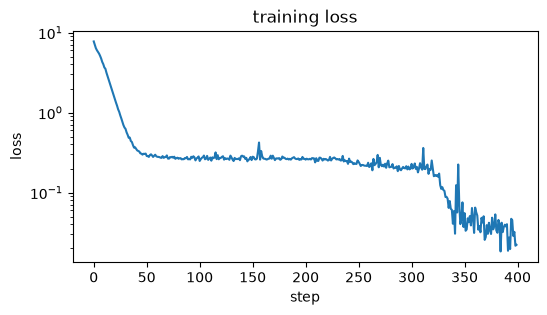

In [5]:
t = time.time()
metrics = train_synthetic_vlm(model, steps=400, batch_size=32, lr=1e-3)
print(f"{time.time() - t:.0f}s, loss {metrics.initial_loss:.2f} -> {metrics.final_loss:.3f}")

plt.figure(figsize=(6, 3))
plt.plot(metrics.loss_history)
plt.yscale("log")
plt.xlabel("step"); plt.ylabel("loss")
plt.title("training loss");

The loss drops fast to around 0.3 - that's the model learning the template "a ___ ___ in the ___ ___". The second, slower drop is when it starts actually reading the image. With only ~100 steps it stays on the plateau and the captions below are mostly wrong; 400 steps gets most of them, and ~800 gets all of them.

The test images are freshly drawn (new noise), but they're the same 24 colour/shape/position combinations as in training, so this checks that the model reads the image, not that it generalises.

exact-match on 64 freshly drawn images: 0.859375


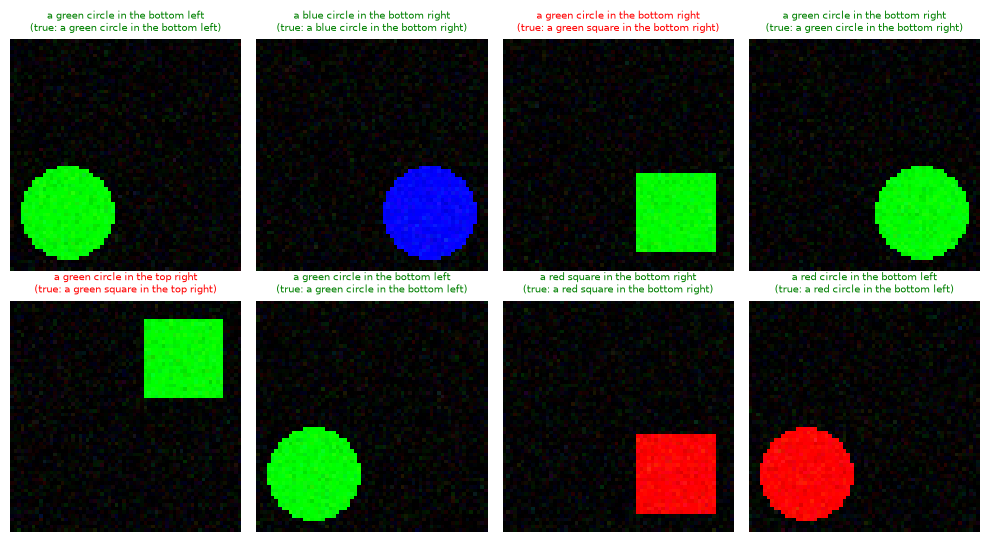

In [6]:
test = SyntheticMultimodalDataset(num_samples=8, image_size=cfg.vision.image_size, seed=123)
after = model.generate(test.images, torch.ones(8, 1, dtype=torch.long), max_new_tokens=10)

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax, img, cap, row in zip(axes.flat, test.images, test.captions, after):
    pred = decode_caption(row[1:])
    ax.imshow(img.clamp(0, 1).permute(1, 2, 0))
    ax.set_title(f"{pred}\n(true: {cap})", fontsize=7, color="green" if pred == cap else "red")
    ax.axis("off")
plt.tight_layout()

print("exact-match on 64 freshly drawn images:", caption_accuracy(model))

## 4. KV cache

Without a cache, every new token re-runs the decoder over the full sequence: 17 image tokens + prompt + everything generated so far. With the cache, each step only processes the one new token and attends over stored keys/values.

The outputs have to be identical - the cache is purely an optimisation.

identical: True


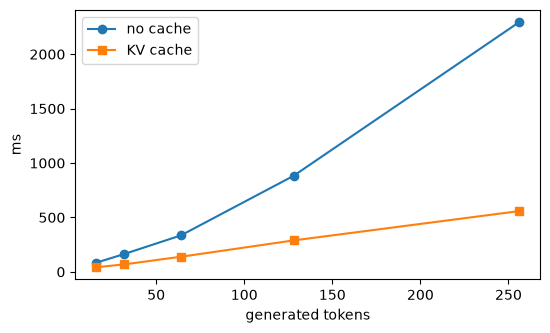

In [7]:
imgs = test.images[:1]
prompt = torch.randint(4, cfg.text.vocab_size, (1, 16))
a = model.generate(imgs, prompt, max_new_tokens=64, use_kv_cache=True)
b = model.generate(imgs, prompt, max_new_tokens=64, use_kv_cache=False)
print("identical:", torch.equal(a, b))

lengths = [16, 32, 64, 128, 256]
cached, uncached = [], []
for n in lengths:
    for use, store in [(True, cached), (False, uncached)]:
        t = time.perf_counter()
        model.generate(imgs, prompt, max_new_tokens=n, use_kv_cache=use)
        store.append((time.perf_counter() - t) * 1000)

plt.figure(figsize=(6, 3.5))
plt.plot(lengths, uncached, "o-", label="no cache")
plt.plot(lengths, cached, "s-", label="KV cache")
plt.xlabel("generated tokens"); plt.ylabel("ms"); plt.legend();

Note the cached version isn't constant per token either - each step still attends over the whole history, so a step costs O(T). It's the "recompute every layer for every old token" part that goes away.

## 5. Paged KV cache

A contiguous cache has to reserve `max_seq_len` slots per sequence up front. The paged cache hands out fixed-size blocks (4 tokens here, 16 in the benchmark) as sequences grow, and takes them back when a sequence finishes - same idea as vLLM.

Below, 3 requests with different lengths go through the continuous-batching loop with room for 2 at a time. Afterwards every block is back in the free list.

In [8]:
reqs = []
for i, (plen, n_new) in enumerate([(3, 6), (10, 2), (5, 4)]):
    reqs.append(Request(i, test.images[i], torch.randint(4, cfg.text.vocab_size, (plen,)), n_new))

stats = run_continuous_batching(model, reqs, max_batch_size=2, num_blocks=64, block_size=4)
print(stats)
for r in reqs:
    ref = model.generate(r.image[None], r.prompt_ids[None], max_new_tokens=r.max_new_tokens)[0, len(r.prompt_ids):].tolist()
    print(f"request {r.request_id}: {r.output}  same as generate(): {r.output == ref}")

SchedulerStats(num_requests=3, generated_tokens=12, wall_time_s=0.042802075000054174, decode_steps=5, mean_decode_step_ms=3.7603745999149396, peak_blocks_in_use=13, peak_kv_mb=0.076171875)
request 0: [4, 6, 9, 10, 11, 13]  same as generate(): True
request 1: [4, 7]  same as generate(): True
request 2: [4, 6, 9, 10]  same as generate(): True


And the block table for one sequence, to see the indirection:

In [9]:
cache = model.create_paged_cache(num_blocks=16, block_size=4)
model.prefill_paged(test.images[:1], torch.randint(4, 100, (1, 5)), cache, seq_id=0)  # 17 + 5 = 22 tokens
model.prefill_paged(test.images[1:2], torch.randint(4, 100, (1, 2)), cache, seq_id=1)  # 19 tokens
print("seq lengths: ", cache.seq_lengths)
print("block tables:", cache.block_tables)
print("free blocks: ", len(cache.free_blocks))
print(cache.memory_comparison(max_seq_len=cfg.text.max_seq_len))

seq lengths:  {0: 22, 1: 19}
block tables: {0: [0, 1, 2, 3, 4, 5], 1: [6, 7, 8, 9, 10]}
free blocks:  5
{'num_sequences': 2.0, 'paged_allocated_mb': 0.064453125, 'contiguous_allocated_mb': 1.5, 'active_token_mb': 0.06005859375, 'vram_savings_pct': 95.703125, 'paged_internal_fragmentation_pct': 6.818181818181824}


22 tokens need 6 blocks of 4, 19 tokens need 5. A contiguous cache sized for `max_seq_len=512` would hold 512 slots each.

That comparison against max_seq_len is where the big "90% saved" numbers come from. If you already know the longest request and size the contiguous cache for that, the paged cache only saves a bit (the benchmark report shows both).

## 6. ONNX + int8

Export to two ONNX graphs, quantize the weights to int8, and check the outputs still agree with PyTorch.

In [10]:
import tempfile
from pathlib import Path
from quantization import export_vlm_to_onnx, ONNXVLMRunner, evaluate_quantization_quality

out = Path(tempfile.mkdtemp())
paths = export_vlm_to_onnx(model, out)
for p in sorted(out.iterdir()):
    print(f"{p.name:28s} {p.stat().st_size / 1e6:6.2f} MB")

int8 = ONNXVLMRunner(cfg, paths.vision_int8, paths.decoder_int8, paths.token_embed_int8, providers=["CPUExecutionProvider"])
report = evaluate_quantization_quality(model, int8, paths)
print()
print(f"size {report.fp32_size_mb:.1f} MB -> {report.int8_size_mb:.1f} MB ({report.compression_ratio:.2f}x)")
print(f"cosine {report.logit_cosine_similarity:.5f}, top-1 agreement {report.top1_token_agreement_pct:.1f}%")
print(f"perplexity {report.pytorch_perplexity:.3f} (fp32) vs {report.onnx_perplexity:.3f} (int8)")

decoder_kv_fp32.onnx           6.54 MB
decoder_kv_int8.onnx           1.88 MB
token_embeddings.npy           1.57 MB
token_embeddings_int8.npz      0.40 MB
vision_projector_fp32.onnx     2.27 MB
vision_projector_int8.onnx     0.93 MB



size 9.9 MB -> 3.1 MB (3.23x)
cosine 1.00000, top-1 agreement 100.0%
perplexity 1.025 (fp32) vs 1.025 (int8)


The int8 variant quantizes the graph weights and keeps a per-row int8 copy of the embedding table for the host-side lookup. It doesn't reach 4x because LayerNorm/bias weights and the quantization scales stay fp32, and the tied embedding matrix is stored twice (once for the lookup, once as `lm_head` inside the decoder graph).